# Exploration du dataset Cloud — CIC-IDS2017

Objectif : vérifier la structure, les classes, la qualité des données et les endpoints
avant le feature engineering.

In [1]:
import sys
!{sys.executable} -m pip install seaborn

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "cicids_sample.parquet"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Racine du projet :", PROJECT_ROOT)
print("Dataset trouvé :", DATA_PATH.exists())

sns.set_theme(style="whitegrid")

Racine du projet : c:\Users\lahni\Desktop\ensa\PFA\project
Dataset trouvé : True


In [3]:
import pyarrow.parquet as pq

# Lecture du schéma sans charger les données.
parquet_file = pq.ParquetFile(DATA_PATH)
available_columns = parquet_file.schema.names

wanted_columns = [
    "Source IP",
    "Destination IP",
    "Destination Port",
    "Protocol",
    "Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Average Packet Size",
    "Label",
    "target",
]

columns_to_load = [
    column for column in wanted_columns
    if column in available_columns
]

print("Colonnes chargées :", columns_to_load)

df = pd.read_parquet(DATA_PATH, columns=columns_to_load)
df.columns = df.columns.str.strip()

print(f"Nombre de flows : {len(df):,}")
print(f"Nombre de colonnes chargées : {len(df.columns)}")

df.head()

Colonnes chargées : ['Source IP', 'Destination IP', 'Destination Port', 'Protocol', 'Flow Duration', 'Flow Bytes/s', 'Flow Packets/s', 'Average Packet Size', 'Label', 'target']
Nombre de flows : 577,846
Nombre de colonnes chargées : 10


,Source IP,Destination IP,Destination Port,Protocol,Flow Duration,Flow Bytes/s,Flow Packets/s,Average Packet Size,Label,target
0,192.168.10.3,192.168.10.1,53,17,60443,4.285029e+03,33.089026,151.50,BENIGN,0
1,23.194.108.211,192.168.10.15,60701,6,314,1.560510e+05,12738.853500,13.75,BENIGN,0
2,217.160.72.6,192.168.10.8,2523,6,3,4.000000e+06,666666.666700,9.00,BENIGN,0
3,192.168.10.14,23.61.187.27,80,6,116078738,1.953846e+01,0.258445,75.60,BENIGN,0
4,192.168.10.12,192.168.10.3,53,17,192,2.041667e+06,20833.333330,108.25,BENIGN,0


In [4]:
print("Colonnes disponibles :\n")

for i, column in enumerate(df.columns, start=1):
    print(f"{i:>2}. {column}")

Colonnes disponibles :

 1. Source IP
 2. Destination IP
 3. Destination Port
 4. Protocol
 5. Flow Duration
 6. Flow Bytes/s
 7. Flow Packets/s
 8. Average Packet Size
 9. Label
10. target


In [5]:
class_counts = df["target"].value_counts().sort_index()

print("0 = BENIGN | 1 = ATTACK\n")
print(class_counts)

class_percentages = (class_counts / len(df) * 100).round(2)
print("\nPourcentages :")
print(class_percentages)

0 = BENIGN | 1 = ATTACK

target
0    288923
1    288923
Name: count, dtype: int64

Pourcentages :
target
0    50.0
1    50.0
Name: count, dtype: float64


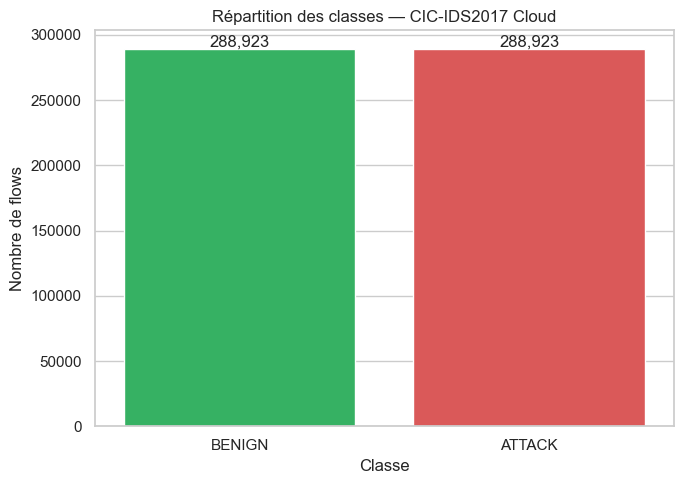

Figure sauvegardée : c:\Users\lahni\Desktop\ensa\PFA\project\reports\figures\class_distribution.png


In [6]:
plot_labels = df["target"].map({
    0: "BENIGN",
    1: "ATTACK"
})

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    x=plot_labels,
    order=["BENIGN", "ATTACK"],
    hue=plot_labels,
    palette={"BENIGN": "#22C55E", "ATTACK": "#EF4444"},
    legend=False
)

plt.title("Répartition des classes — CIC-IDS2017 Cloud")
plt.xlabel("Classe")
plt.ylabel("Nombre de flows")

for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}")

plt.tight_layout()

output = FIGURES_DIR / "class_distribution.png"
plt.savefig(output, dpi=150)
plt.show()

print(f"Figure sauvegardée : {output}")

In [7]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("Colonnes contenant des valeurs manquantes :")

if missing.empty:
    print("Aucune valeur manquante.")
else:
    print(missing)

numeric_df = df.select_dtypes(include=np.number)

infinite_count = np.isinf(numeric_df).sum().sum()
print(f"\nNombre total de valeurs infinies : {infinite_count:,}")

Colonnes contenant des valeurs manquantes :
Aucune valeur manquante.

Nombre total de valeurs infinies : 0


In [8]:
print("Nombre d'IP source uniques :", df["Source IP"].nunique())
print("Nombre d'IP destination uniques :", df["Destination IP"].nunique())

print("\nTop 10 IP source :")
print(df["Source IP"].value_counts().head(10))

print("\nTop 10 IP destination :")
print(df["Destination IP"].value_counts().head(10))

Nombre d'IP source uniques : 6561
Nombre d'IP destination uniques : 8816

Top 10 IP source :
Source IP
172.16.0.1       287067
192.168.10.3      40086
192.168.10.50     25866
192.168.10.5      24050
192.168.10.9      23038
192.168.10.12     22489
192.168.10.15     22405
192.168.10.14     19937
192.168.10.19     16876
192.168.10.16     16369
Name: count, dtype: int64

Top 10 IP destination :
Destination IP
192.168.10.50    290112
192.168.10.3      84354
192.168.10.1      39484
172.16.0.1        20276
192.168.10.5       5256
192.168.10.15      5000
192.168.10.9       4736
192.168.10.14      4677
192.168.10.12      4567
192.168.10.16      4119
Name: count, dtype: int64


In [9]:
main_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Average Packet Size",
]

available_features = [
    feature for feature in main_features
    if feature in df.columns
]

df[available_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Flow Duration,577846.0,1.053567e+07,2.785768e+07,-13.0,59.000000,30653.000000,1.870805e+06,1.199999e+08
Flow Bytes/s,577846.0,9.432325e+05,1.984347e+07,-193000000.0,160.555627,17394.536185,1.666667e+05,2.071000e+09
Flow Packets/s,577846.0,4.377249e+04,1.735253e+05,-2000000.0,3.794192,133.111481,3.448276e+04,3.000000e+06
Average Packet Size,577846.0,2.593005e+02,4.690106e+02,0.0,5.000000,34.000000,1.633636e+02,2.528000e+03


In [10]:
duplicates = df.duplicated().sum()

print(f"Flows dupliqués : {duplicates:,}")
print(f"Flows exploitables : {len(df):,}")

print("""
Conclusion :
- Les classes sont équilibrées.
- Les colonnes Source IP et Destination IP sont disponibles.
- Le dataset est prêt pour feature_engineering.py,
  après validation des valeurs manquantes et infinies ci-dessus.
""")

Flows dupliqués : 83,363
Flows exploitables : 577,846

Conclusion :
- Les classes sont équilibrées.
- Les colonnes Source IP et Destination IP sont disponibles.
- Le dataset est prêt pour feature_engineering.py,
  après validation des valeurs manquantes et infinies ci-dessus.

